## Delft3D-FM animation with timeseries
This script reads the map.nc file and generates the animation. This script is designed to also add the animation of the boundary condition timeseries. The user can select a specific time period and a specific portion of the study area.

In [1]:
# general python packages
import os
import datetime as dt

# packages for data manipulation
import numpy as np
import pandas as pd
import xarray as xr

# packages for visualization
# Plotting settings
import matplotlib
matplotlib.rcParams['font.family'] = 'Arial'
matplotlib.rcParams['axes.titlesize'] = 15  # Title size
matplotlib.rcParams['axes.labelsize'] = 14  # Axis label size
matplotlib.rcParams['xtick.labelsize'] = 13  # X tick labels size
matplotlib.rcParams['ytick.labelsize'] = 13  # Y tick labels size
matplotlib.rcParams['legend.fontsize'] = 13  # Legend label size

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as ticker
from matplotlib.animation import FuncAnimation, FFMpegWriter
import contextily as ctx
#import cmocean.cm as cmo
from cmcrameri import cm

# packages for Delft3D FM (by Deltares)
import hydrolib.core.dflowfm as hcdfm
import dfm_tools as dfmt

import geopandas as gpd

def read_ldb(filename):
    """Read Delft3D .ldb file and return list of boundary polygons (as arrays of x,y).
    We use this function to deliniate the subaerial islands of the Chattahoochee delta
    """
    boundaries = []
    with open(filename, "r") as f:
        lines = f.readlines()
    
    i = 0
    while i < len(lines):
        line = lines[i].strip()
        
        # Skip empty lines
        if not line:
            i += 1
            continue
        
        # Block starts with 'Fxxx'
        if line.startswith("F"):
            # Next line has rows and cols
            i += 1
            nrows, ncols = map(int, lines[i].split())
            
            coords = []
            for j in range(nrows):
                i += 1
                x, y = map(float, lines[i].split())
                coords.append((x, y))
            
            boundaries.append(coords)
        i += 1
    
    return boundaries

### Parameters and loading

In [15]:
# --- Configuration ---
sim_location = '//researchdata/DVLdata/Snyderlab/LakeSeminole/Luca/SSC_weir_aug_oct2023_R17'
map_netcdf   = os.path.join(sim_location, 'dflowfm/output', '*_map.nc')
bc_file      = os.path.join(sim_location, 'dflowfm', "Discharge.bc")
output_folder = os.path.join(sim_location, 'post_processing')

if not os.path.exists(output_folder):
    os.makedirs(output_folder)

# Time and Space settings
period  = 'None'
zoom    = 'Yes'
tin_str = '2023-08-20 00:00:00'
tend_str= '2023-08-27 00:00:00'

# Coordinates (Chattahoochee delta)
lon_min, lon_max = 68800, 703000
lat_min, lat_max = 339000, 3410500

##################### Load Map #######################
map_xr = dfmt.open_partitioned_dataset(map_netcdf)

# Time Slicing
t = map_xr.time
if period != 'all':
    t = t.sel(time=slice(tin_str, tend_str))
#######################################################

# Load domain and Chattahoochee delta islands contours
# domain    
domain_shp = 'model_domain.shp'
gdf_aoi = gpd.read_file(domain_shp)

# islands boundaries
ldb_file = "delta_island.ldb"
islands  = read_ldb(ldb_file)

>> xu.open_dataset() with 14 partition(s): 1 2 3 4 5 6 7 8 9 10 11 12 13 14 : 6.31 sec
>> xu.merge_partitions() with 14 partition(s): 6.97 sec
>> dfmt.open_partitioned_dataset() total: 13.29 sec


### Vectorial variable

Rasterizing vectors...
>> rasterizing ugrid Dataset with 2 face variables to shape=(53,27): 0.04 sec
Setting up animation...
Starting animation of 120 frames...
Animation as C:/Users/cortel/Desktop/Lake_Seminole_model/8_1_hydro_weir/weir_downstream\post_processing\flow_speed_BC_69000_339000.mp4


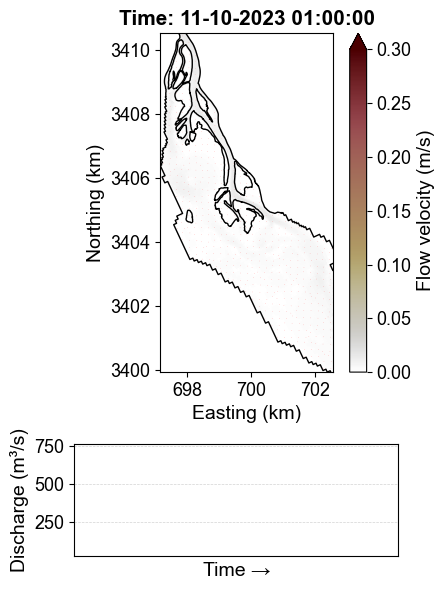

In [6]:
# Visualization settings
c_min, c_max   = 0.0, 0.3
varn_ucx, varn_ucy = 'mesh2d_ucx', 'mesh2d_ucy'
rasterize_res  = 200
quiver_scale   = 4
quiver_color   = 'red' 

# Create reference time arrays
t_ref = pd.to_datetime("2010-01-01")
map_datetimes = pd.to_datetime(t.values)
map_seconds = (map_datetimes - t_ref).total_seconds().astype(int)

# BC Parsing 
bc_data = []
with open(bc_file, "r") as f:
    # Skip header (first 8 lines)
    for _ in range(8):
        next(f)
    
    # Read data block
    for line in f:
        line = line.strip()
        if not line: break # Stop at empty line
        
        parts = line.split()
        if len(parts) != 2: break # Stop if not 2 columns (header of next block)
        
        try:
            # Parse time and value
            time_val = float(parts[0])
            flow_val = float(parts[1])
            bc_data.append((time_val, flow_val))
        except ValueError:
            break # Stop if parsing fails (text found)

# Create DataFrame and filter to match simulation times
df = pd.DataFrame(bc_data, columns=["time_sec", "value"])

# Filter BC data to only include times present in the map output
# using isin is much faster than looping
df = df[df['time_sec'].isin(map_seconds)].reset_index(drop=True)
df['datetime'] = t_ref + pd.to_timedelta(df['time_sec'], unit='s')

# Slice map data spatially and temporally
uds_quiv = map_xr.sel(time=t)
if zoom:
    uds_quiv = uds_quiv.ugrid.sel(x=slice(lon_min, lon_max), y=slice(lat_min, lat_max))

# Calculate Magnitude for ALL time steps at once (Vectorized)
mag_data = np.sqrt(uds_quiv[varn_ucx]**2 + uds_quiv[varn_ucy]**2)
uds_quiv['magn'] = mag_data.where(uds_quiv['mesh2d_waterdepth'] != 0, np.nan).load()

# Rasterize vectors (Pre-calculate coordinates)
# We only rasterize the structure once; we'll update values later
print("Rasterizing vectors...")
raster_quiv = dfmt.rasterize_ugrid(uds_quiv[[varn_ucx, varn_ucy]], resolution=rasterize_res).load()

# Extract X, Y for quivers once
qv_x = raster_quiv['mesh2d_face_x'].values
qv_y = raster_quiv['mesh2d_face_y'].values

print("Setting up animation...")
fig, ax = plt.subplots(2, 1, figsize=(4.5, 6), gridspec_kw={'height_ratios': [3, 1]})

# Speed Map
poly_plot = uds_quiv.isel(time=0)['magn'].ugrid.plot(ax=ax[0], cmap=cm.bamako_r, add_colorbar=True, cbar_kwargs={'extend': 'max'})
poly_plot.set_clim(c_min, c_max)
poly_plot.colorbar.set_label('Flow velocity (m/s)')

# Quivers
u_0 = raster_quiv[varn_ucx].isel(time=0).values
v_0 = raster_quiv[varn_ucy].isel(time=0).values
qv = ax[0].quiver(qv_x, qv_y, u_0, v_0, color=quiver_color, scale=quiver_scale)

ax[0].set_xlabel('Easting (km)')
ax[0].set_ylabel('Northing (km)')
title_text = ax[0].set_title(f"Time: {map_datetimes[0].strftime('%d-%m-%Y %H:%M:%S')}", fontweight = 'bold')

# Convert meters to kilometers (only visually)
ax[0].xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{x/1000:g}"))
ax[0].yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, pos: f"{y/1000:g}"))

# Islands and domain contours
gdf_aoi.plot(ax=ax[0], facecolor='none', edgecolor='k', linewidth=1, linestyle='-')
for coords in islands:
    xs, ys = zip(*coords)
    ax[0].plot(list(xs), list(ys), color="k", linewidth=1)

# Discharge Time Series
line_plot, = ax[1].plot([], [], lw=2) # Initialize empty line
ax[1].set_xlim(df['datetime'].min(), df['datetime'].max())
ax[1].set_ylim(df['value'].min(), df['value'].max() * 1.1)
ax[1].set_ylabel('Discharge (m\u00b3/s)')
ax[1].set_xlabel('Time →')
ax[1].set_xticks([])
ax[1].grid(True, which='both', color='lightgrey', linestyle='--', linewidth=0.5)

fig.tight_layout()

def animate(i):
    # Update Speed Map
    new_mag = uds_quiv['magn'].isel(time=i).values
    poly_plot.set_array(new_mag) 
    
    # Update Quivers (new U and V data)
    new_u = raster_quiv[varn_ucx].isel(time=i).values
    new_v = raster_quiv[varn_ucy].isel(time=i).values
    qv.set_UVC(new_u, new_v)
    
    # Update Title
    title_text.set_text(f"Time: {map_datetimes[i].strftime('%d-%m-%Y %H:%M:%S')}")
    
    # Update Discharge Line
    current_time = map_seconds[i]
    df_slice = df[df.time_sec <= current_time]
    line_plot.set_data(df_slice.datetime, df_slice.value)
    
    return poly_plot, qv, title_text, line_plot

# Create Animation
print(f"Starting animation of {len(t)} frames...")
ani = FuncAnimation(fig, animate, frames=len(t), interval=200, blit=False)

# Save
if zoom:
    ani_file = os.path.join(output_folder, f'flow_speed_BC_{lon_min}_{lat_min}.mp4')
else:
    ani_file = os.path.join(output_folder, 'flow_speed_BC.mp4')

writer = FFMpegWriter(fps=5, bitrate=2000)
ani.save(ani_file, writer=writer, dpi=300)
print(f"Animation as {ani_file}")

### Scalar variable

Starting animation of 169 frames...
Animation as //researchdata/DVLdata/Snyderlab/LakeSeminole/Luca/SSC_weir_aug_oct2023_R17\post_processing\mesh2d_sedfrac_concentration_BC_68800_339000.mp4


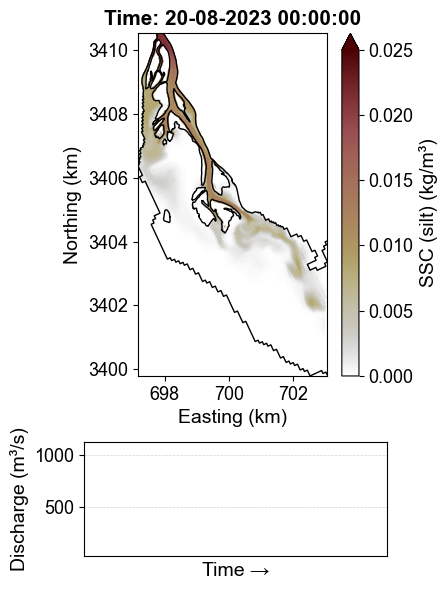

In [18]:
# =============  Set a few properties =======================
fraction_name = "silt"
c_min      = 0   # Minimum value
c_max      = 0.025 # Maximum value
variable   = 'mesh2d_sedfrac_concentration'
magn_attrs = {'long_name': f'SSC ({fraction_name})', 'units': 'kg/m\u00b3'}
# ==========================================================

if variable == 'mesh2d_sedfrac_concentration':
    # =====================================================================
    # With sediment there are multiple fractions
    sed_names = [name.decode('utf-8') for name in map_xr["sedfrac_name"].values]
    i_frac = sed_names.index(fraction_name)

    # Select the time slice (if selected) and sediment fraction
    plot_data = map_xr["mesh2d_sedfrac_concentration"].sel(time = t, nSedSus=i_frac)
# =====================================================================
else:
    plot_data = map_xr[variable].sel(time=t)
# Slice map data spatially if specific area is specified
if zoom:
    plot_data = plot_data.ugrid.sel(x=slice(lon_min, lon_max), y=slice(lat_min, lat_max))

# Create reference time arrays
t_ref = pd.to_datetime("2010-01-01")
map_datetimes = pd.to_datetime(t.values)
map_seconds = (map_datetimes - t_ref).total_seconds().astype(int)

# BC Parsing 
bc_data = []
with open(bc_file, "r") as f:
    # Skip header (first 8 lines)
    for _ in range(8):
        next(f)
    
    # Read data block
    for line in f:
        line = line.strip()
        if not line: break # Stop at empty line
        
        parts = line.split()
        if len(parts) != 2: break # Stop if not 2 columns (header of next block)
        
        try:
            # Parse time and value
            time_val = float(parts[0])
            flow_val = float(parts[1])
            bc_data.append((time_val, flow_val))
        except ValueError:
            break # Stop if parsing fails (text found)

# Create DataFrame and filter to match simulation times
df = pd.DataFrame(bc_data, columns=["time_sec", "value"])

# Filter BC data to only include times present in the map output
# using isin is much faster than looping
df = df[df['time_sec'].isin(map_seconds)].reset_index(drop=True)
df['datetime'] = t_ref + pd.to_timedelta(df['time_sec'], unit='s')

# Plot Setup
fig, ax = plt.subplots(2, 1, figsize=(4.5, 6), gridspec_kw={'height_ratios': [3, 1]})

# Scalar variable
poly_plot = plot_data.isel(time=0).ugrid.plot(ax=ax[0], cmap=cm.bilbao_r, add_colorbar=True, cbar_kwargs={'extend': 'max'})
poly_plot.set_clim(c_min, c_max)
poly_plot.colorbar.set_label(magn_attrs["long_name"] + ' (' + magn_attrs["units"] + ')')

ax[0].set_xlabel('Easting (km)')
ax[0].set_ylabel('Northing (km)')
title_text = ax[0].set_title(f"Time: {map_datetimes[0].strftime('%d-%m-%Y %H:%M:%S')}", fontweight = 'bold')

# Convert meters to kilometers (only visually)
ax[0].xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{x/1000:g}"))
ax[0].yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, pos: f"{y/1000:g}"))

# Islands and domain contours
gdf_aoi.plot(ax=ax[0], facecolor='none', edgecolor='k', linewidth=1, linestyle='-')
for coords in islands:
    xs, ys = zip(*coords)
    ax[0].plot(list(xs), list(ys), color="k", linewidth=1)

# Discharge Time Series
line_plot, = ax[1].plot([], [], lw=2) # Initialize empty line
ax[1].set_xlim(df['datetime'].min(), df['datetime'].max())
ax[1].set_ylim(df['value'].min(), df['value'].max() * 1.1)
ax[1].set_ylabel('Discharge (m\u00b3/s)')
ax[1].set_xlabel('Time →')
ax[1].set_xticks([])
ax[1].grid(True, which='both', color='lightgrey', linestyle='--', linewidth=0.5)

fig.tight_layout()

def animate(i):
    # Update Map
    new_mag = plot_data.isel(time=i).values
    poly_plot.set_array(new_mag) 
    
    # Update Title
    title_text.set_text(f"Time: {map_datetimes[i].strftime('%d-%m-%Y %H:%M:%S')}")
    
    current_time = map_seconds[i]
    # Slice the dataframe up to the current time
    df_slice = df[df.time_sec <= current_time]
    line_plot.set_data(df_slice.datetime, df_slice.value)
    
    return poly_plot, title_text, line_plot

# Create Animation
# frames is len(t) to match the data length exactly
print(f"Starting animation of {len(t)} frames...")
ani = FuncAnimation(fig, animate, frames=len(t), interval=200, blit=False)

# Save
if zoom:
    ani_file = os.path.join(output_folder, f'{variable}_BC_{lon_min}_{lat_min}.mp4')
else:
    ani_file = os.path.join(output_folder, f'{variable}_BC.mp4')

writer = FFMpegWriter(fps=5, bitrate=2000)
ani.save(ani_file, writer=writer, dpi=300)
print(f"Animation as {ani_file}")